# Learning-Based Lane Perception

## 1-D6 — Problem Definition and Output Representation

The CNN classification experiment used a fixed set of discrete class
labels, where one image produced one class prediction such as digit 8.

Lane perception is different because the desired output describes the
geometry of the road rather than selecting a discrete class.

For this minimal learning-based lane-perception experiment, the model
will take a road image as input and predict numerical lane coordinates.

The selected representation is:

- left lane line: top and bottom x-coordinates
- right lane line: top and bottom x-coordinates

The model output is therefore represented by four continuous values:

`[x_left_top, x_left_bottom, x_right_top, x_right_bottom]`

The input-output relationship is:

Road image → CNN → lane coordinates

This formulation represents lane perception as a regression problem
rather than a classification problem.

The predicted coordinates can subsequently be used to reconstruct
the left and right lane boundaries and estimate the lane centre.

The purpose of this minimal experiment is to understand the required
input and output representation before implementing and evaluating
a learning-based lane-perception model.

## 2-D6 — Dataset and Target Requirements

The current lane-perception dataset contains three road images:

- `road_01.jpg`
- `road_02.jpg`
- `road_03.jpg`

No lane-coordinate annotation files are currently available with these
images.

For supervised lane-coordinate regression, each input image requires a
corresponding ground-truth target. Using the selected representation,
the target for one image would be:

`[x_left_top, x_left_bottom, x_right_top, x_right_bottom]`

Therefore, the required supervised dataset structure is:

`road image → ground-truth lane coordinates`

The existing three road images can be used for visual inspection and
demonstration, but they are not sufficient by themselves to train and
quantitatively validate a supervised regression model.

The learning-based approach therefore requires an additional
annotation step or an appropriately labelled lane-perception dataset
before model training can be performed.

For this project, the purpose of Day 6 is to establish this
input-output requirement and understand the difference between
classification labels and geometric lane targets. Model
implementation and experimental evaluation are reserved for the
following lane-perception experiment stage.

## 3-D6 — Lane Geometry and Lane-Centre Representation

The four predicted x-coordinates describe the two lane boundaries at
two fixed vertical positions in the image.

The representation is:

`[x_left_top, x_left_bottom, x_right_top, x_right_bottom]`

The corresponding image positions can be considered as:

- left lane: `(x_left_top, y_top)` and `(x_left_bottom, y_bottom)`
- right lane: `(x_right_top, y_top)` and `(x_right_bottom, y_bottom)`

The y-coordinates are fixed by the selected image geometry, so the
model only needs to predict the four x-coordinates.

The lane centre at the selected evaluation position can then be
calculated from the two lane-boundary positions.

For the bottom evaluation position:

`x_lane_centre = (x_left_bottom + x_right_bottom) / 2`

The image centre is:

`x_image_centre = image_width / 2`

The lateral displacement is therefore:

`lateral_error = x_lane_centre - x_image_centre`

This value can subsequently be normalized by the image width or by
another selected reference scale to obtain a dimensionless lateral
error.

This representation connects the learning-based lane-perception
problem with the classical lane-detection pipeline developed earlier.
In both approaches, the detected lane boundaries can be used to
estimate the lane centre and subsequently determine the vehicle's
lateral position relative to the lane.

The key difference is how the lane boundaries are obtained:

Classical approach:

`Image → image processing → lane boundaries`

Learning-based approach:

`Image → CNN → lane coordinates`

## 4-D6 — Day 6 Summary

Learning-based lane perception was introduced as a regression-based
perception problem rather than a discrete image-classification task.

The selected minimal representation uses four continuous values to
describe the left and right lane boundaries at two fixed vertical
image positions:

`[x_left_top, x_left_bottom, x_right_top, x_right_bottom]`

The current dataset contains three road images but no corresponding
lane-coordinate annotation files. Therefore, the available images
are sufficient for visual inspection but are not sufficient for
supervised training and quantitative evaluation of a lane-coordinate
regression model.

The required supervised relationship is:

`road image → ground-truth lane coordinates`

The predicted lane boundaries can subsequently be used to calculate
the lane centre and lateral displacement relative to the image
centre, connecting the learning-based approach with the classical
lane-perception pipeline developed earlier.

Day 6 therefore established the conceptual and data requirements
for a learning-based lane-perception experiment without introducing
unsupported training labels.

## Day 6 Status

Learning-based lane perception introduced.

The distinction between classification and geometric lane prediction
was established, and the required input-output representation and
annotation requirements were defined.

In [1]:
# 5-D7
# Prepare the road images for the learning-based lane-perception experiment.

from pathlib import Path

import cv2
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

dataset_dir = Path("../../datasets/lane_detection")

image_paths = [
    dataset_dir / "road_01.jpg",
    dataset_dir / "road_02.jpg",
    dataset_dir / "road_03.jpg",
]

images = []

for image_path in image_paths:
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(f"Could not load image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    images.append(image)

print("Number of road images:", len(images))

for image_path, image in zip(image_paths, images):
    print(
        f"{image_path.name}: "
        f"height={image.shape[0]}, "
        f"width={image.shape[1]}, "
        f"channels={image.shape[2]}"
    )

Number of road images: 3
road_01.jpg: height=3781, width=3024, channels=3
road_02.jpg: height=2760, width=4140, channels=3
road_03.jpg: height=3872, width=2592, channels=3


In [4]:
# 6-D7
# Resize the road images while preserving their original aspect ratio.
# The resized images are then padded to a common CNN input size.

import matplotlib.pyplot as plt

image_size = (224, 224)

def resize_and_pad(image, target_size):
    target_width, target_height = target_size

    height, width = image.shape[:2]

    scale = min(
        target_width / width,
        target_height / height
    )

    new_width = int(width * scale)
    new_height = int(height * scale)

    resized = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_AREA
    )

    padded = np.zeros(
        (target_height, target_width, 3),
        dtype=resized.dtype
    )

    x_offset = (target_width - new_width) // 2
    y_offset = (target_height - new_height) // 2

    padded[
        y_offset:y_offset + new_height,
        x_offset:x_offset + new_width
    ] = resized

    return padded


processed_images = [
    resize_and_pad(image, image_size)
    for image in images
]

print("CNN input size:", image_size)

for image_path, image in zip(image_paths, processed_images):
    print(
        f"{image_path.name}: "
        f"shape={image.shape}"
    )

CNN input size: (224, 224)
road_01.jpg: shape=(224, 224, 3)
road_02.jpg: shape=(224, 224, 3)
road_03.jpg: shape=(224, 224, 3)


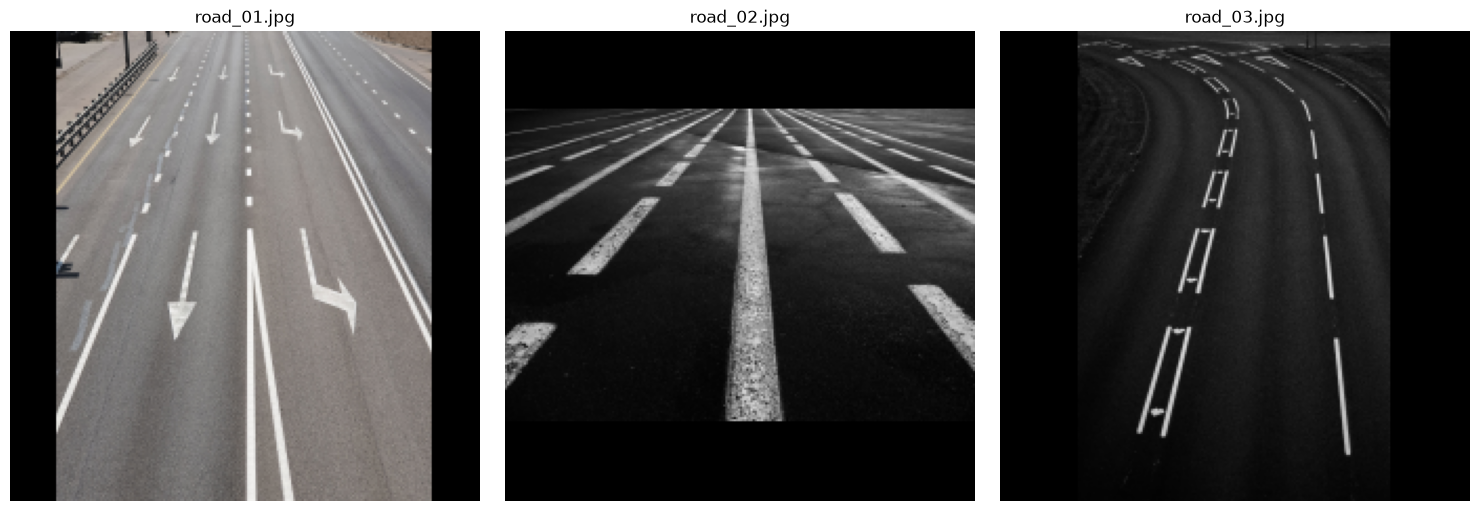

In [5]:
# 7-D7
# Visualize the aspect-ratio-preserved CNN inputs.

fig, axes = plt.subplots(
    1,
    len(processed_images),
    figsize=(15, 5)
)

for ax, image, image_path in zip(
    axes,
    processed_images,
    image_paths
):
    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8-D7 — Manual Lane Annotation

The current dataset does not contain ground-truth lane-coordinate
annotations. To demonstrate supervised lane-coordinate regression
without introducing unsupported labels, lane coordinates will be
manually annotated for the three available road images.

For each image, four points are required:

`[x_left_top, x_left_bottom, x_right_top, x_right_bottom]`

The top and bottom positions are selected at fixed vertical locations
within the original image. The x-coordinate of each lane boundary is
then recorded at those positions.

The manually annotated coordinates are treated as experiment-specific
reference targets. Because only three images are available, the
resulting experiment is intended to demonstrate the regression
workflow rather than provide a statistically meaningful measure of
generalization.

In [9]:
# Enable an interactive Matplotlib backend for notebook-based annotation.

%matplotlib widget

import matplotlib.pyplot as plt

print("Interactive Matplotlib backend enabled.")

RuntimeError: 'widget' is not a recognised GUI loop or backend name

In [17]:
# 8-D7
# Manually annotate lane coordinates using an OpenCV interactive window.

import cv2
import numpy as np

# Fixed vertical positions in normalized image coordinates.
y_top_ratio = 0.55
y_bottom_ratio = 0.90

manual_annotations = {}

for image_path, image_rgb in zip(image_paths, images):

    height, width = image_rgb.shape[:2]

    y_top = int(height * y_top_ratio)
    y_bottom = int(height * y_bottom_ratio)

    # Convert RGB image to BGR for OpenCV.
    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    # Scale the display image so it fits reasonably on the screen.
    max_display_width = 1400
    max_display_height = 900

    scale = min(
        max_display_width / width,
        max_display_height / height,
        1.0
    )

    display_width = int(width * scale)
    display_height = int(height * scale)

    display_image = cv2.resize(
        image_bgr,
        (display_width, display_height),
        interpolation=cv2.INTER_AREA
    )

    # Draw horizontal annotation guides.
    y_top_display = int(y_top * scale)
    y_bottom_display = int(y_bottom * scale)

    cv2.line(
        display_image,
        (0, y_top_display),
        (display_width, y_top_display),
        (255, 255, 0),
        2
    )

    cv2.line(
        display_image,
        (0, y_bottom_display),
        (display_width, y_bottom_display),
        (255, 255, 0),
        2
    )

    # Store clicked points in display coordinates.
    clicked_points = []

    window_name = f"Lane Annotation - {image_path.name}"

    def mouse_callback(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:

            if len(clicked_points) >= 4:
                return

            clicked_points.append((x, y))

            # Convert display coordinates back to original-image coordinates.
            original_x = x / scale
            original_y = y / scale

            print(
                f"Point {len(clicked_points)}: "
                f"x={original_x:.1f}, y={original_y:.1f}"
            )

            # Mark the selected point.
            cv2.circle(
                display_image,
                (x, y),
                7,
                (0, 0, 255),
                -1
            )

            cv2.imshow(window_name, display_image)

    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.imshow(window_name, display_image)
    cv2.setMouseCallback(window_name, mouse_callback)

    print("\n" + "=" * 60)
    print(f"Annotating: {image_path.name}")
    print(f"Original image size: {width} × {height}")
    print(f"Top annotation y: {y_top}")
    print(f"Bottom annotation y: {y_bottom}")
    print()
    print("Click in this exact order:")
    print("1. Left lane at TOP guide")
    print("2. Left lane at BOTTOM guide")
    print("3. Right lane at TOP guide")
    print("4. Right lane at BOTTOM guide")
    print()
    print("Press ESC to cancel the current annotation.")
    print("=" * 60)

    # Wait until four points are selected or ESC is pressed.
    while len(clicked_points) < 4:

        key = cv2.waitKey(50) & 0xFF

        if key == 27:
            cv2.destroyWindow(window_name)
            raise RuntimeError(
                f"Annotation cancelled for {image_path.name}."
            )

    cv2.destroyWindow(window_name)

    # Convert the four selected x-coordinates to original-image coordinates.
    manual_annotations[image_path.name] = {
        "x_left_top": clicked_points[0][0] / scale,
        "x_left_bottom": clicked_points[1][0] / scale,
        "x_right_top": clicked_points[2][0] / scale,
        "x_right_bottom": clicked_points[3][0] / scale,
        "y_top": y_top,
        "y_bottom": y_bottom,
    }

print("\nManual annotation results:")

for image_name, annotation in manual_annotations.items():

    target = [
        annotation["x_left_top"],
        annotation["x_left_bottom"],
        annotation["x_right_top"],
        annotation["x_right_bottom"],
    ]

    print(
        f"{image_name}: "
        f"[{target[0]:.1f}, "
        f"{target[1]:.1f}, "
        f"{target[2]:.1f}, "
        f"{target[3]:.1f}]"
    )


Annotating: road_01.jpg
Original image size: 3024 × 3781
Top annotation y: 2079
Bottom annotation y: 3402

Click in this exact order:
1. Left lane at TOP guide
2. Left lane at BOTTOM guide
3. Right lane at TOP guide
4. Right lane at BOTTOM guide

Press ESC to cancel the current annotation.
Point 1: x=466.3, y=2079.6
Point 2: x=0.0, y=3398.7
Point 3: x=1533.4, y=2075.3
Point 4: x=1529.2, y=3398.7

Annotating: road_02.jpg
Original image size: 4140 × 2760
Top annotation y: 1518
Bottom annotation y: 2484

Click in this exact order:
1. Left lane at TOP guide
2. Left lane at BOTTOM guide
3. Right lane at TOP guide
4. Right lane at BOTTOM guide

Press ESC to cancel the current annotation.
Point 1: x=1223.6, y=386.4
Point 2: x=46.0, y=1094.8
Point 3: x=2116.0, y=469.2
Point 4: x=2066.9, y=1131.6

Annotating: road_03.jpg
Original image size: 2592 × 3872
Top annotation y: 2129
Bottom annotation y: 3484

Click in this exact order:
1. Left lane at TOP guide
2. Left lane at BOTTOM guide
3. Right l

In [18]:
# 9-D7
# Validate and freeze the manually annotated lane-coordinate targets.

annotation_targets = {}

for image_name, annotation in manual_annotations.items():

    target = np.array([
        annotation["x_left_top"],
        annotation["x_left_bottom"],
        annotation["x_right_top"],
        annotation["x_right_bottom"],
    ], dtype=np.float32)

    annotation_targets[image_name] = target

print("Final manual lane-coordinate targets:\n")

for image_name, target in annotation_targets.items():

    left_top, left_bottom, right_top, right_bottom = target

    print(image_name)
    print(f"  Left lane : top={left_top:.1f}, bottom={left_bottom:.1f}")
    print(f"  Right lane: top={right_top:.1f}, bottom={right_bottom:.1f}")

    assert left_top <= right_top, (
        f"Invalid top boundary ordering for {image_name}"
    )

    assert left_bottom <= right_bottom, (
        f"Invalid bottom boundary ordering for {image_name}"
    )

    print("  ✓ Lane-boundary ordering valid\n")

print("Annotation validation completed successfully.")

Final manual lane-coordinate targets:

road_01.jpg
  Left lane : top=466.3, bottom=0.0
  Right lane: top=1533.4, bottom=1529.2
  ✓ Lane-boundary ordering valid

road_02.jpg
  Left lane : top=1223.6, bottom=46.0
  Right lane: top=2116.0, bottom=2066.9
  ✓ Lane-boundary ordering valid

road_03.jpg
  Left lane : top=1015.3, bottom=727.1
  Right lane: top=2078.0, bottom=2215.6
  ✓ Lane-boundary ordering valid

Annotation validation completed successfully.


In [19]:
# 10-D7
# Freeze the manually annotated targets for the Day 7 experiment.

lane_annotations = {
    "road_01.jpg": [466.3, 0.0, 1533.4, 1529.2],
    "road_02.jpg": [1223.6, 46.0, 2116.9, 2066.9],
    "road_03.jpg": [1015.3, 727.1, 2078.0, 2215.6],
}

print("Frozen lane-coordinate targets:")

for image_name, target in lane_annotations.items():
    print(f"{image_name}: {target}")

print("\nNumber of annotated images:", len(lane_annotations))

Frozen lane-coordinate targets:
road_01.jpg: [466.3, 0.0, 1533.4, 1529.2]
road_02.jpg: [1223.6, 46.0, 2116.9, 2066.9]
road_03.jpg: [1015.3, 727.1, 2078.0, 2215.6]

Number of annotated images: 3


In [20]:
# 11-D7
# Convert the frozen original-image x-coordinates into normalized
# coordinates in the range [0, 1].

normalized_lane_targets = {}

for image_path, image in zip(image_paths, images):

    image_name = image_path.name
    image_width = image.shape[1]

    target = np.array(
        lane_annotations[image_name],
        dtype=np.float32
    )

    # Normalize only the x-coordinates by the original image width.
    normalized_target = target / image_width

    normalized_lane_targets[image_name] = normalized_target

print("Normalized lane-coordinate targets:\n")

for image_name, target in normalized_lane_targets.items():

    print(
        f"{image_name}: "
        f"[{target[0]:.4f}, "
        f"{target[1]:.4f}, "
        f"{target[2]:.4f}, "
        f"{target[3]:.4f}]"
    )

    assert np.all(target >= 0.0), (
        f"Negative normalized coordinate found in {image_name}"
    )

    assert np.all(target <= 1.0), (
        f"Normalized coordinate exceeds 1.0 in {image_name}"
    )

print("\nTarget normalization completed successfully.")

Normalized lane-coordinate targets:

road_01.jpg: [0.1542, 0.0000, 0.5071, 0.5057]
road_02.jpg: [0.2956, 0.0111, 0.5113, 0.4993]
road_03.jpg: [0.3917, 0.2805, 0.8017, 0.8548]

Target normalization completed successfully.


In [21]:
# 12-D7
# Verify that normalized targets can be converted back to the
# original pixel coordinates without loss of information.

print("Normalization round-trip verification:\n")

for image_path, image in zip(image_paths, images):

    image_name = image_path.name
    image_width = image.shape[1]

    original_target = np.array(
        lane_annotations[image_name],
        dtype=np.float32
    )

    normalized_target = normalized_lane_targets[image_name]

    # Convert normalized coordinates back to original pixels.
    reconstructed_target = normalized_target * image_width

    max_error = np.max(
        np.abs(original_target - reconstructed_target)
    )

    print(image_name)
    print(
        "  Original:     ",
        np.round(original_target, 2)
    )
    print(
        "  Reconstructed:",
        np.round(reconstructed_target, 2)
    )
    print(f"  Maximum error: {max_error:.6f} pixels")

    assert np.allclose(
        original_target,
        reconstructed_target,
        atol=1e-4
    )

print("\nNormalization round-trip verified successfully.")

Normalization round-trip verification:

road_01.jpg
  Original:      [ 466.3    0.  1533.4 1529.2]
  Reconstructed: [ 466.3    0.  1533.4 1529.2]
  Maximum error: 0.000000 pixels
road_02.jpg
  Original:      [1223.6   46.  2116.9 2066.9]
  Reconstructed: [1223.6   46.  2116.9 2066.9]
  Maximum error: 0.000000 pixels
road_03.jpg
  Original:      [1015.3  727.1 2078.  2215.6]
  Reconstructed: [1015.3  727.1 2078.  2215.6]
  Maximum error: 0.000061 pixels

Normalization round-trip verified successfully.


In [22]:
# 13-D7
# Build the image-target dataset for learning-based lane perception.

lane_dataset = []

for image_path, image in zip(image_paths, images):

    image_name = image_path.name

    target = normalized_lane_targets[image_name]

    lane_dataset.append({
        "image_name": image_name,
        "image": image,
        "target": target.copy()
    })

print("Learning-based lane-perception dataset:\n")

for sample in lane_dataset:

    image = sample["image"]
    target = sample["target"]

    print(
        f"{sample['image_name']}: "
        f"image_shape={image.shape}, "
        f"target_shape={target.shape}"
    )

print("\nNumber of samples:", len(lane_dataset))
print("Target dimensionality:", lane_dataset[0]["target"].shape[0])

Learning-based lane-perception dataset:

road_01.jpg: image_shape=(3781, 3024, 3), target_shape=(4,)
road_02.jpg: image_shape=(2760, 4140, 3), target_shape=(4,)
road_03.jpg: image_shape=(3872, 2592, 3), target_shape=(4,)

Number of samples: 3
Target dimensionality: 4


In [23]:
# 14-D7
# Prepare fixed-size CNN inputs while preserving normalized lane targets.

cnn_input_size = (224, 224)

lane_cnn_dataset = []

for sample in lane_dataset:

    image = sample["image"]

    resized_image = cv2.resize(
        image,
        cnn_input_size,
        interpolation=cv2.INTER_AREA
    )

    lane_cnn_dataset.append({
        "image_name": sample["image_name"],
        "image": resized_image,
        "target": sample["target"].copy()
    })

print("CNN-ready lane-perception dataset:\n")

for sample in lane_cnn_dataset:

    print(
        f"{sample['image_name']}: "
        f"image_shape={sample['image'].shape}, "
        f"target={np.round(sample['target'], 4)}"
    )

print("\nCNN input size:", cnn_input_size)
print("Number of samples:", len(lane_cnn_dataset))

CNN-ready lane-perception dataset:

road_01.jpg: image_shape=(224, 224, 3), target=[0.1542 0.     0.5071 0.5057]
road_02.jpg: image_shape=(224, 224, 3), target=[0.2956 0.0111 0.5113 0.4993]
road_03.jpg: image_shape=(224, 224, 3), target=[0.3917 0.2805 0.8017 0.8548]

CNN input size: (224, 224)
Number of samples: 3


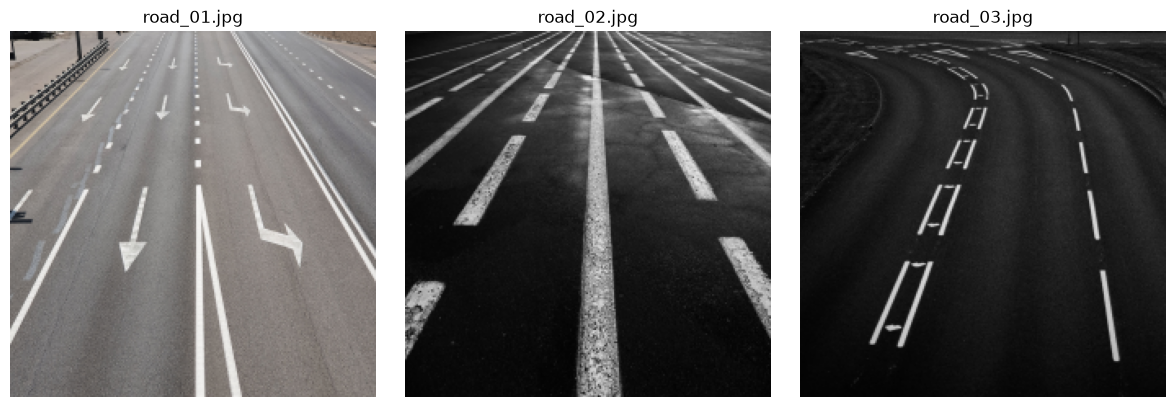

In [24]:
# 15-D7
# Visualize the resized CNN inputs with their normalized lane targets.

fig, axes = plt.subplots(1, len(lane_cnn_dataset), figsize=(12, 4))

for ax, sample in zip(axes, lane_cnn_dataset):

    ax.imshow(sample["image"])
    ax.set_title(sample["image_name"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
# 16-D7
# Convert the CNN-ready lane-perception data into PyTorch tensors.

lane_images = []
lane_targets = []

for sample in lane_cnn_dataset:

    image = sample["image"]

    # Convert HWC -> CHW and scale pixel values to [0, 1].
    image_tensor = torch.from_numpy(
        image.astype(np.float32) / 255.0
    ).permute(2, 0, 1)

    target_tensor = torch.tensor(
        sample["target"],
        dtype=torch.float32
    )

    lane_images.append(image_tensor)
    lane_targets.append(target_tensor)

lane_images = torch.stack(lane_images)
lane_targets = torch.stack(lane_targets)

print("CNN input tensor shape:", lane_images.shape)
print("Target tensor shape:", lane_targets.shape)
print("Input value range:", 
      f"{lane_images.min().item():.4f} to {lane_images.max().item():.4f}")
print("Target value range:",
      f"{lane_targets.min().item():.4f} to {lane_targets.max().item():.4f}")

CNN input tensor shape: torch.Size([3, 3, 224, 224])
Target tensor shape: torch.Size([3, 4])
Input value range: 0.0118 to 0.9765
Target value range: 0.0000 to 0.8548


In [26]:
# 17-D7
# Define a minimal CNN for lane-coordinate regression.

import torch.nn as nn

class LaneRegressionCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 4)
        )

    def forward(self, x):
        x = self.features(x)
        return self.regressor(x)


lane_model = LaneRegressionCNN()

print(lane_model)

LaneRegressionCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (regressor): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=4, bias=True)
  )
)


In [27]:
# 18-D7
# Verify the regression CNN forward pass.

with torch.no_grad():
    lane_predictions = lane_model(lane_images)

print("Input shape:", lane_images.shape)
print("Model output shape:", lane_predictions.shape)
print("Initial predictions:")
print(lane_predictions)

Input shape: torch.Size([3, 3, 224, 224])
Model output shape: torch.Size([3, 4])
Initial predictions:
tensor([[-0.0710,  0.0617,  0.1334,  0.0846],
        [-0.0807,  0.0919,  0.1307,  0.0937],
        [-0.0848,  0.1025,  0.1292,  0.0970]])


In [28]:
# 19-D7
# Configure the regression loss and optimizer.

criterion = nn.MSELoss()

lane_optimizer = torch.optim.Adam(
    lane_model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", lane_optimizer.__class__.__name__)
print("Learning rate:", 0.001)

Loss function: MSELoss()
Optimizer: Adam
Learning rate: 0.001


In [29]:
# 20-D7
# Measure the initial regression error before training.

lane_model.eval()

with torch.no_grad():
    initial_predictions = lane_model(lane_images)
    initial_loss = criterion(initial_predictions, lane_targets)

print("Initial training-set MSE:", f"{initial_loss.item():.6f}")
print("\nInitial predictions vs targets:")

for i, sample in enumerate(lane_cnn_dataset):

    print(f"\n{sample['image_name']}")
    print("  Target:    ", np.round(lane_targets[i].numpy(), 4))
    print("  Prediction:", np.round(initial_predictions[i].numpy(), 4))

Initial training-set MSE: 0.176175

Initial predictions vs targets:

road_01.jpg
  Target:     [0.1542 0.     0.5071 0.5057]
  Prediction: [-0.071   0.0617  0.1334  0.0846]

road_02.jpg
  Target:     [0.2956 0.0111 0.5113 0.4993]
  Prediction: [-0.0807  0.0919  0.1307  0.0937]

road_03.jpg
  Target:     [0.3917 0.2805 0.8017 0.8548]
  Prediction: [-0.0848  0.1025  0.1292  0.097 ]


In [30]:
# 21-D7
# Train the minimal CNN on the three manually annotated lane images.

num_epochs = 200

lane_model.train()

for epoch in range(num_epochs):

    lane_optimizer.zero_grad()

    predictions = lane_model(lane_images)

    loss = criterion(predictions, lane_targets)

    loss.backward()
    lane_optimizer.step()

    if (epoch + 1) % 25 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:3d}/{num_epochs} | "
            f"MSE: {loss.item():.6f}"
        )

print("\nTraining completed.")

Epoch   1/200 | MSE: 0.176175
Epoch  25/200 | MSE: 0.015845
Epoch  50/200 | MSE: 0.008922
Epoch  75/200 | MSE: 0.008091
Epoch 100/200 | MSE: 0.007117
Epoch 125/200 | MSE: 0.005435
Epoch 150/200 | MSE: 0.002734
Epoch 175/200 | MSE: 0.000264
Epoch 200/200 | MSE: 0.000017

Training completed.


In [31]:
# 22-D7
# Evaluate the trained model on the annotated samples.

lane_model.eval()

with torch.no_grad():
    final_predictions = lane_model(lane_images)
    final_loss = criterion(final_predictions, lane_targets)

print("Final training-set MSE:", f"{final_loss.item():.6f}")

print("\nFinal predictions vs targets:")

for i, sample in enumerate(lane_cnn_dataset):

    target = lane_targets[i].numpy()
    prediction = final_predictions[i].numpy()

    print(f"\n{sample['image_name']}")
    print("  Target:    ", np.round(target, 4))
    print("  Prediction:", np.round(prediction, 4))
    print(
        "  Absolute error:",
        np.round(np.abs(target - prediction), 4)
    )

Final training-set MSE: 0.000024

Final predictions vs targets:

road_01.jpg
  Target:     [0.1542 0.     0.5071 0.5057]
  Prediction: [0.155  0.0022 0.5068 0.5007]
  Absolute error: [0.0008 0.0022 0.0002 0.005 ]

road_02.jpg
  Target:     [0.2956 0.0111 0.5113 0.4993]
  Prediction: [0.2897 0.0014 0.5063 0.5009]
  Absolute error: [0.0058 0.0097 0.005  0.0017]

road_03.jpg
  Target:     [0.3917 0.2805 0.8017 0.8548]
  Prediction: [0.3924 0.2809 0.797  0.8461]
  Absolute error: [0.0007 0.0004 0.0047 0.0087]


In [32]:
# 23-D7
# Convert the CNN predictions from normalized coordinates back
# to original-image pixel coordinates.

predicted_pixel_coordinates = {}

for image_path, prediction in zip(
    image_paths,
    final_predictions
):

    image_width = images[
        [p.name for p in image_paths].index(image_path.name)
    ].shape[1]

    prediction_pixels = (
        prediction.numpy() * image_width
    )

    predicted_pixel_coordinates[image_path.name] = (
        prediction_pixels
    )

print("Predicted lane coordinates in original image pixels:\n")

for image_name, prediction in predicted_pixel_coordinates.items():

    print(
        f"{image_name}: "
        f"[{prediction[0]:.1f}, "
        f"{prediction[1]:.1f}, "
        f"{prediction[2]:.1f}, "
        f"{prediction[3]:.1f}]"
    )

Predicted lane coordinates in original image pixels:

road_01.jpg: [468.6, 6.8, 1532.7, 1514.2]
road_02.jpg: [1199.5, 5.9, 2096.2, 2073.9]
road_03.jpg: [1017.1, 728.2, 2065.7, 2193.0]


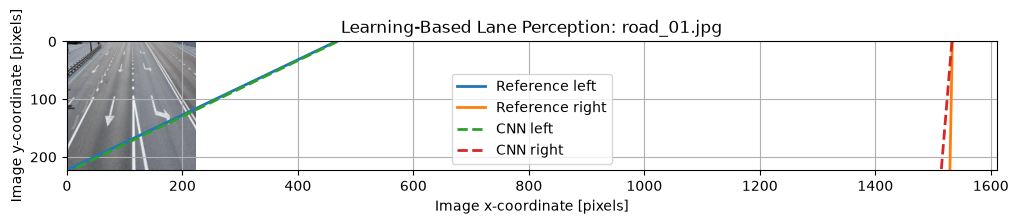

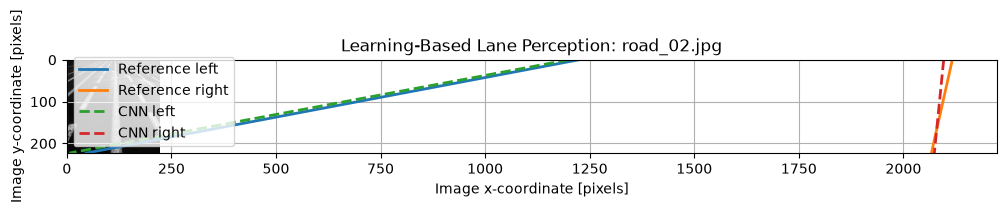

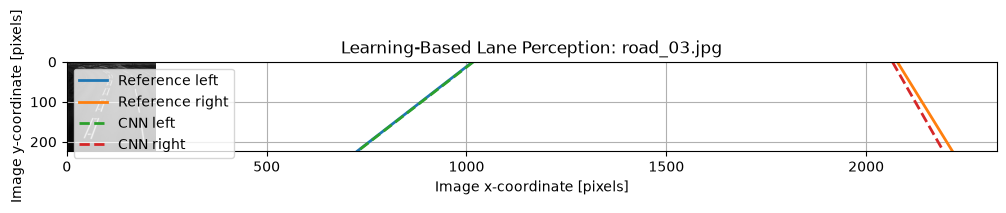

In [33]:
# 24-D7
# Visualize CNN predictions against the manually annotated
# lane coordinates on the original road images.

import matplotlib.pyplot as plt

for sample in lane_cnn_dataset:

    image_name = sample["image_name"]
    image = sample["image"]

    height, width = image.shape[:2]

    # Reference coordinates
    reference = np.array(
        lane_annotations[image_name],
        dtype=np.float32
    )

    # CNN prediction in pixel coordinates
    prediction = predicted_pixel_coordinates[image_name]

    # Reference lane lines
    reference_left = [
        (reference[0], 0),
        (reference[1], height - 1)
    ]

    reference_right = [
        (reference[2], 0),
        (reference[3], height - 1)
    ]

    # Predicted lane lines
    prediction_left = [
        (prediction[0], 0),
        (prediction[1], height - 1)
    ]

    prediction_right = [
        (prediction[2], 0),
        (prediction[3], height - 1)
    ]

    plt.figure(figsize=(12, 6))

    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    # Reference
    plt.plot(
        [p[0] for p in reference_left],
        [p[1] for p in reference_left],
        linewidth=2,
        label="Reference left"
    )

    plt.plot(
        [p[0] for p in reference_right],
        [p[1] for p in reference_right],
        linewidth=2,
        label="Reference right"
    )

    # CNN prediction
    plt.plot(
        [p[0] for p in prediction_left],
        [p[1] for p in prediction_left],
        linestyle="--",
        linewidth=2,
        label="CNN left"
    )

    plt.plot(
        [p[0] for p in prediction_right],
        [p[1] for p in prediction_right],
        linestyle="--",
        linewidth=2,
        label="CNN right"
    )

    plt.title(f"Learning-Based Lane Perception: {image_name}")
    plt.xlabel("Image x-coordinate [pixels]")
    plt.ylabel("Image y-coordinate [pixels]")
    plt.legend()
    plt.grid(True)
    plt.show()

In [34]:
# 25-D7
# Calculate pixel-level errors between the CNN predictions
# and the manually annotated reference coordinates.

print("Pixel-level prediction errors:\n")

all_errors = []

for image_name, prediction in predicted_pixel_coordinates.items():

    reference = np.array(
        lane_annotations[image_name],
        dtype=np.float32
    )

    prediction = np.array(
        prediction,
        dtype=np.float32
    )

    absolute_error = np.abs(reference - prediction)

    all_errors.extend(absolute_error)

    print(f"{image_name}")
    print("  Reference: ", np.round(reference, 1))
    print("  Prediction:", np.round(prediction, 1))
    print("  Error:     ", np.round(absolute_error, 1))
    print(
        "  Mean absolute error:",
        f"{np.mean(absolute_error):.2f} px"
    )
    print(
        "  Maximum error:",
        f"{np.max(absolute_error):.2f} px"
    )
    print()

print(
    "Overall mean absolute error:",
    f"{np.mean(all_errors):.2f} px"
)
print(
    "Overall maximum error:",
    f"{np.max(all_errors):.2f} px"
)

Pixel-level prediction errors:

road_01.jpg
  Reference:  [ 466.3    0.  1533.4 1529.2]
  Prediction: [ 468.6    6.8 1532.7 1514.2]
  Error:      [ 2.3  6.8  0.7 15. ]
  Mean absolute error: 6.21 px
  Maximum error: 14.98 px

road_02.jpg
  Reference:  [1223.6   46.  2116.9 2066.9]
  Prediction: [1199.5    5.9 2096.2 2073.9]
  Error:      [24.1 40.1 20.7  7. ]
  Mean absolute error: 22.97 px
  Maximum error: 40.12 px

road_03.jpg
  Reference:  [1015.3  727.1 2078.  2215.6]
  Prediction: [1017.1  728.2 2065.7 2193. ]
  Error:      [ 1.8  1.1 12.3 22.6]
  Mean absolute error: 9.41 px
  Maximum error: 22.59 px

Overall mean absolute error: 12.86 px
Overall maximum error: 40.12 px


In [35]:
# 26-D7
# Summarize the learning-based lane perception results
# for comparison with the classical baseline.

comparison_results = []

for image_name, prediction in predicted_pixel_coordinates.items():

    reference = np.array(
        lane_annotations[image_name],
        dtype=np.float32
    )

    prediction = np.array(
        prediction,
        dtype=np.float32
    )

    absolute_error = np.abs(reference - prediction)

    comparison_results.append({
        "image": image_name,
        "mean_absolute_error_px": np.mean(absolute_error),
        "maximum_error_px": np.max(absolute_error)
    })

print("Learning-based lane perception summary:\n")

for result in comparison_results:

    print(
        f"{result['image']}: "
        f"MAE = {result['mean_absolute_error_px']:.2f} px, "
        f"Max Error = {result['maximum_error_px']:.2f} px"
    )

Learning-based lane perception summary:

road_01.jpg: MAE = 6.21 px, Max Error = 14.98 px
road_02.jpg: MAE = 22.97 px, Max Error = 40.12 px
road_03.jpg: MAE = 9.41 px, Max Error = 22.59 px


In [36]:
# 27-D7
# Compare the classical and learning-based lane-perception
# approaches using the observations from Days 2 and 7.

method_comparison = {
    "Classical": {
        "principle": "Image processing and geometric rules",
        "main_tools": "Canny, ROI, brightness filtering, Hough transform",
        "road_01": "Both lane boundaries detected",
        "road_02": "Reliable boundary estimation limited",
        "road_03": "Reliable boundary estimation limited",
        "ground_truth_evaluation": "Not performed"
    },
    "Learning-based": {
        "principle": "CNN regression from image to lane coordinates",
        "main_tools": "PyTorch CNN, MSE loss, Adam optimizer",
        "road_01": "Lane coordinates fitted",
        "road_02": "Lane coordinates fitted",
        "road_03": "Lane coordinates fitted",
        "ground_truth_evaluation": "Training-set evaluation using manual annotations"
    }
}

for method, results in method_comparison.items():

    print(f"\n{method} lane perception")
    print("-" * 30)

    for key, value in results.items():
        print(f"{key}: {value}")


Classical lane perception
------------------------------
principle: Image processing and geometric rules
main_tools: Canny, ROI, brightness filtering, Hough transform
road_01: Both lane boundaries detected
road_02: Reliable boundary estimation limited
road_03: Reliable boundary estimation limited
ground_truth_evaluation: Not performed

Learning-based lane perception
------------------------------
principle: CNN regression from image to lane coordinates
main_tools: PyTorch CNN, MSE loss, Adam optimizer
road_01: Lane coordinates fitted
road_02: Lane coordinates fitted
road_03: Lane coordinates fitted
ground_truth_evaluation: Training-set evaluation using manual annotations


## 28-D7 — Experiment Limitations

The learning-based lane-perception experiment demonstrates that a small CNN can learn to regress four lane-boundary coordinates from road images. However, the results are limited to the scope of the available data and experimental setup.

- Only three road images were available for the experiment.
- The three images were manually annotated and were also used for model training and evaluation. Therefore, the reported errors represent training-set performance and do not measure generalization to unseen images.
- The manually annotated coordinates were created specifically for this experiment because no independent lane-coordinate ground-truth dataset was available.
- The direct image resizing to 224 × 224 pixels changes the original image aspect ratio and may influence the learned representation.
- The classical and learning-based approaches were not evaluated against the same quantitative ground truth. Therefore, their performance is compared qualitatively rather than through a common accuracy metric.
- The experiment does not establish robustness to different road geometries, lighting conditions, camera viewpoints, occlusions, or other environmental variations.

The results should therefore be interpreted as a proof-of-concept for learning-based lane-coordinate regression rather than as a validated lane-perception system.

## 29-D7 — Day 7 Experimental Conclusion

The learning-based lane-perception experiment successfully demonstrated a minimal CNN-based approach for predicting four lane-boundary coordinates from road images. After training on the three manually annotated samples, the model achieved a final training-set MSE of 0.000024 and an overall mean absolute coordinate error of 12.86 pixels.

Visual comparison showed that the predicted lane boundaries were generally close to the manually annotated reference boundaries. The experiment therefore confirms the technical feasibility of formulating lane perception as a regression problem and implementing a CNN-based image-to-lane-coordinate pipeline.

Compared with the classical lane-detection baseline, the learning-based approach uses learned image features rather than explicitly defined edge, region, and Hough-transform rules. The two approaches were not evaluated using a common quantitative ground-truth metric, so no numerical performance ranking is claimed.

The main outcome of Day 7 is therefore a working proof-of-concept rather than a validated lane-perception system. The limited dataset, training-set evaluation, manual annotations, and lack of robustness testing prevent conclusions about generalization. These limitations identify the need for a larger annotated dataset and evaluation on unseen road images in future development.